# CredScore AI: Decifrando o Risco de Crédito
## Notebook 02 — Modelagem, avaliação, explicabilidade (SHAP) e equidade

| | |
|---|---|
| **Instituição** | Universidade Presbiteriana Mackenzie — Faculdade de Computação e Informática |
| **Disciplina** | Inteligência Artificial — 7º CC |
| **Professor** | Prof. Dr. Ivan Carlos Alcântara de Oliveira |
| **Integrante** | Rodrigo Daiske Uehara — RA 10440295 — 10440295@mackenzista.com.br |

**Síntese do conteúdo do arquivo.** Este notebook implementa a etapa da N2 do projeto:
(1) confirma no dicionário original do UCI o significado dos valores ausentes e a origem das
9 variáveis da versão simplificada; (2) define o protocolo experimental (divisão estratificada
70/30, validação cruzada estratificada repetida 5×2, ajuste de hiperparâmetros e matriz de custo 5:1);
(3) treina e compara Regressão Logística, Random Forest e XGBoost com duas estratégias de
balanceamento (peso de classe e SMOTENC dentro de cada partição); (4) escolhe o limiar de decisão
pelo custo esperado em predições fora da dobra; (5) avalia o modelo final no teste com intervalos
de confiança por *bootstrap*, incluindo calibração; (6) explica o modelo com SHAP; (7) avalia a
equidade por taxas de erro entre grupos (sexo e faixa etária) com incerteza amostral; (8) testa
uma medida de mitigação (remoção dos atributos sensíveis); (9) mede o efeito da redução de 20 para
9 atributos; e (10) salva o modelo usado pelo protótipo (`app/app.py`).

**Histórico de alterações**

| Data | Autor | Descrição da atualização |
|---|---|---|
| 15/10/2026 | Rodrigo Daiske Uehara | Criação do notebook: protocolo experimental, treino e ajuste dos três modelos, limiar por custo, calibração, SHAP, equidade, mitigação e análise de sensibilidade. |

## 1. Configuração do ambiente

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
import sklearn, xgboost, imblearn
from scipy.stats import loguniform
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import precision_recall_curve, confusion_matrix
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     StratifiedKFold, RandomizedSearchCV)

sys.path.append(str(Path('..') / 'src'))
import credscore as cs   # funções compartilhadas com o protótipo

warnings.filterwarnings('ignore')
DADOS, RES = Path('../dados'), Path('../resultados')
FIG, MOD = RES / 'figuras', Path('../modelos')
for p in (FIG, RES, MOD):
    p.mkdir(parents=True, exist_ok=True)

CORES = {'LR': '#2a78d6', 'RF': '#eb6834', 'XGB': '#1baf7a', 'Base': '#8a8986'}
NOMES = {'LR': 'Regressão Logística', 'RF': 'Random Forest', 'XGB': 'XGBoost'}
BAL = {'peso': 'peso de classe', 'smotenc': 'SMOTENC'}
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
pd.set_option('display.precision', 3)
np.random.seed(cs.SEED)
print(f'scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | '
      f'imbalanced-learn {imblearn.__version__} | shap {shap.__version__}')

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scikit-learn 1.9.1 | xgboost 3.4.1 | imbalanced-learn 0.14.2 | shap 0.53.0


## 2. Dados: fonte exata, dicionário e significado dos valores ausentes

O parecer da N1 pediu (i) a fonte exata da versão simplificada, (ii) a lista dos nove preditores,
(iii) a justificativa da redução da base e (iv) a confirmação, **no dicionário**, do significado dos
ausentes. Para isso, cruzamos registro a registro o arquivo usado no projeto
(`german_credit_data.csv`, 9 preditores) com o arquivo original do UCI (`german.data`, 20 atributos
codificados, cópia em `dados/german_original_uci.csv`, dicionário em `dados/german_original_uci.names`).

In [2]:
simp = pd.read_csv(DADOS / 'german_credit_data.csv', index_col=0)
orig = pd.read_csv(DADOS / 'german_original_uci.csv', header=None)
orig.columns = ['checking', 'duration', 'history', 'purpose', 'amount', 'savings', 'employment',
                'installment_rate', 'personal_status_sex', 'other_debtors', 'residence', 'property',
                'age', 'other_plans', 'housing', 'n_credits', 'job', 'liable', 'telephone',
                'foreign_worker', 'class']

# As 1.000 linhas estão na mesma ordem: numéricas e rótulo coincidem exatamente
iguais = {
    'Age': (simp['Age'].values == orig['age'].values).all(),
    'Credit amount': (simp['Credit amount'].values == orig['amount'].values).all(),
    'Duration': (simp['Duration'].values == orig['duration'].values).all(),
    'Risk (bad = classe 2)': ((simp['Risk'] == 'bad').values == (orig['class'] == 2).values).all(),
}
print('Coincidência registro a registro:', iguais)

Coincidência registro a registro: {'Age': np.True_, 'Credit amount': np.True_, 'Duration': np.True_, 'Risk (bad = classe 2)': np.True_}


In [3]:
print('Checking account (projeto) x Atributo 1 do UCI')
display(pd.crosstab(simp['Checking account'].fillna('AUSENTE'), orig['checking']))
print('Saving accounts (projeto) x Atributo 6 do UCI')
display(pd.crosstab(simp['Saving accounts'].fillna('AUSENTE'), orig['savings']))

Checking account (projeto) x Atributo 1 do UCI


checking,A11,A12,A13,A14
Checking account,,,,
AUSENTE,0,0,0,394
little,274,0,0,0
moderate,0,269,0,0
rich,0,0,63,0


Saving accounts (projeto) x Atributo 6 do UCI


savings,A61,A62,A63,A64,A65
Saving accounts,,,,,
AUSENTE,0,0,0,0,183
little,603,0,0,0,0
moderate,0,103,0,0,0
quite rich,0,0,63,0,0
rich,0,0,0,48,0


**Resultado (confirmado no dicionário `german.names`).** O mapeamento é exato (1 para 1):

| Variável do projeto | Atributo UCI | Categorias (código UCI → significado) |
|---|---|---|
| `Checking account` | A1 — situação da conta corrente | `little` = A11 (saldo **< 0 DM**); `moderate` = A12 (0 a 200 DM); `rich` = A13 (≥ 200 DM ou salário depositado há ≥ 1 ano); **ausente = A14 "no checking account"** |
| `Saving accounts` | A6 — poupança/títulos | `little` = A61 (< 100 DM); `moderate` = A62 (100 a 500); `quite rich` = A63 (500 a 1000); `rich` = A64 (≥ 1000); **ausente = A65 "unknown / no savings account"** |

Consequências para a preparação dos dados (correções em relação à N1):

* O ausente em `Checking account` significa de fato **"não possui conta corrente"** (A14) → categoria `sem_conta`.
* O ausente em `Saving accounts` **não** significa necessariamente "sem poupança": o dicionário o define como
  **"desconhecida ou inexistente"** (A65) → categoria `desconhecida_ou_sem_poupanca`. A interpretação "sem conta" da N1 foi corrigida.
* `little` em conta corrente significa **saldo negativo**, e não "saldo pequeno". Por isso a codificação ordinal usada na N1
  (que colocava "sem conta" abaixo de "saldo negativo") era inadequada; na N2 todas as categóricas usam *one-hot*.

In [4]:
dic = pd.DataFrame([
    ['Age', 'A13 — idade (anos)', 'numérica', '19 a 75'],
    ['Sex', 'A9 — estado civil e sexo (A91–A94)', 'nominal', 'female = A92 (divorciada/separada/casada); male = A91, A93, A94'],
    ['Job', 'A17 — qualificação profissional', 'ordinal 0–3', '0 = desempregado/não qualificado não residente ... 3 = gestor/autônomo/altamente qualificado'],
    ['Housing', 'A15 — moradia', 'nominal', 'own, rent, free'],
    ['Saving accounts', 'A6 — poupança/títulos', 'nominal', 'little, moderate, quite rich, rich, desconhecida_ou_sem_poupanca'],
    ['Checking account', 'A1 — conta corrente', 'nominal', 'little (<0 DM), moderate, rich, sem_conta'],
    ['Credit amount', 'A5 — valor do crédito (DM)', 'numérica', '250 a 18.424'],
    ['Duration', 'A2 — prazo (meses)', 'numérica', '4 a 72'],
    ['Purpose', 'A4 — finalidade', 'nominal', '8 categorias (car = A40+A41; education = A46+A48; vacation/others = A410)'],
], columns=['Preditor', 'Origem no UCI', 'Tipo', 'Valores'])
dic

,Preditor,Origem no UCI,Tipo,Valores
0,Age,A13 — idade (anos),numérica,19 a 75
1,Sex,A9 — estado civil e sexo (A91–A94),nominal,female = A92 (divorciada/separada/casada); mal...
2,Job,A17 — qualificação profissional,ordinal 0–3,0 = desempregado/não qualificado não residente...
3,Housing,A15 — moradia,nominal,"own, rent, free"
4,Saving accounts,A6 — poupança/títulos,nominal,"little, moderate, quite rich, rich, desconheci..."
5,Checking account,A1 — conta corrente,nominal,"little (<0 DM), moderate, rich, sem_conta"
6,Credit amount,A5 — valor do crédito (DM),numérica,250 a 18.424
7,Duration,A2 — prazo (meses),numérica,4 a 72
8,Purpose,A4 — finalidade,nominal,8 categorias (car = A40+A41; education = A46+A...


**Justificativa da redução de 20 para 9 atributos.** A versão simplificada mantém as variáveis cadastrais e
financeiras com nomes legíveis, o que facilita a interpretação das explicações SHAP e a demonstração no protótipo,
e preserva os atributos sensíveis (sexo e idade) necessários à avaliação de equidade. Em contrapartida, perde
atributos sabidamente relevantes, como o histórico de crédito (A3). Como a redução tem custo, ela é **medida**
na Seção 11 (mesmo modelo treinado com os 20 atributos). Observa-se também que o atributo "sexo" da versão
simplificada é derivado de A9, que mistura sexo e estado civil, e que a base não possui mulheres solteiras (A95).

## 3. Protocolo experimental, matriz de custo e metas quantitativas

In [5]:
X, y = cs.load_data(DADOS / 'german_credit_data.csv')
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=cs.SEED)
print(f'Treino: {X_tr.shape[0]} clientes ({y_tr.mean():.1%} maus) | Teste: {X_te.shape[0]} clientes ({y_te.mean():.1%} maus)')

CV_TUNE = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=cs.SEED)   # ajuste e comparação
def oof_proba(pipe, X_, y_, repeats=3):
    # Probabilidades fora da dobra (5 partições estratificadas), médias de 3 repetições.
    P = np.zeros(len(y_))
    for r in range(repeats):
        skf = StratifiedKFold(5, shuffle=True, random_state=cs.SEED + r)
        for tr, va in skf.split(X_, y_):
            m = clone_fit(pipe, X_.iloc[tr], y_.iloc[tr])
            P[va] += m.predict_proba(X_.iloc[va])[:, 1] / repeats
    return P

from sklearn.base import clone
def clone_fit(pipe, X_, y_):
    return clone(pipe).fit(X_, y_)

Treino: 700 clientes (30.0% maus) | Teste: 300 clientes (30.0% maus)


**Protocolo.**

1. **Divisão:** 70% treino / 30% teste, estratificada pela classe, semente 42. O teste só é usado uma vez, ao final.
2. **Validação cruzada:** estratificada, **5 partições repetidas 2 vezes** (10 ajustes por configuração), apenas no treino.
3. **Sem vazamento:** codificação *one-hot*, log/padronização das numéricas e SMOTENC ficam **dentro** do *pipeline*
   e são ajustados só na parte de treino de cada partição.
4. **Balanceamento:** (a) **peso de classe** (`class_weight`/`scale_pos_weight`) e (b) **SMOTENC**, variante do SMOTE para dados
   mistos: interpola as numéricas e atribui às categóricas a categoria mais frequente entre os vizinhos, evitando
   criar categorias inexistentes (como "0,4 de mulher"), problema do SMOTE comum em atributos codificados.
5. **Ajuste de hiperparâmetros:** busca aleatória (`RandomizedSearchCV`) maximizando a **PR-AUC** média.
6. **Seleção do modelo:** maior PR-AUC média na validação cruzada (métrica independente de limiar e adequada a classes desbalanceadas).
7. **Limiar de decisão pelo custo:** a matriz de custo do dicionário original atribui **custo 5** a aprovar um mau pagador (FN) e
   **custo 1** a negar indevidamente um bom pagador (FP). O limiar é o que minimiza o custo médio em predições **fora da dobra** do treino.
8. **Calibração:** Brier e ECE (10 faixas); o modelo final recebe calibração de Platt (sigmoide) com validação cruzada interna.
9. **Incerteza:** intervalos de confiança de 95% por *bootstrap* (2.000 reamostragens) no teste.

**Metas quantitativas (definidas antes do treino; substituem expressões como "diminuir bem"):**

| Meta | Critério | Referência |
|---|---|---|
| M1 | PR-AUC no teste ≥ 0,50 | classificador aleatório = 0,30 |
| M2 | Recall da classe "mau pagador" ≥ 0,70 | — |
| M3 | F1 da classe "mau pagador" ≥ 0,55 | "negar todos" = 0,46 |
| M4 | Custo médio por cliente ≤ 0,60 | "negar todos" = 0,70; "aprovar todos" = 1,50 |
| M5 | Brier < 0,21 e ECE ≤ 0,05 | prever sempre 0,30 → Brier = 0,21 |
| M6 | \|ΔTPR\| e \|ΔFPR\| entre grupos ≤ 0,10 | avaliado com IC 95% |

## 4. Referências de comparação (*baselines*)

In [6]:
def baseline_row(nome, proba, pred):
    m = cs.all_metrics(y_te.values, proba, 0.5)
    m.update({'F1 (mau)': cs.f1_score(y_te, pred, zero_division=0),
              'Recall (mau)': cs.recall_score(y_te, pred, zero_division=0),
              'Custo/cliente': cs.expected_cost(y_te, pred)})
    m['Negativa indevida (FPR)'] = pred[y_te.values == 0].mean()
    return pd.Series(m, name=nome)

p_prior = np.full(len(y_te), y_tr.mean())
baselines = pd.DataFrame([
    baseline_row('Aprovar todos', p_prior, np.zeros(len(y_te), int)),
    baseline_row('Negar todos', p_prior, np.ones(len(y_te), int)),
])[['F1 (mau)', 'Recall (mau)', 'Negativa indevida (FPR)', 'Brier', 'Custo/cliente']]
baselines

,F1 (mau),Recall (mau),Negativa indevida (FPR),Brier,Custo/cliente
Aprovar todos,0.000,0.0,0.0,0.21,1.5
Negar todos,0.462,1.0,1.0,0.21,0.7


## 5. Treino e ajuste de hiperparâmetros (validação cruzada 5×2)

In [7]:
ESPACOS = {
    'LR':  {'model__C': loguniform(1e-3, 1e2), 'model__penalty': ['l1', 'l2']},
    'RF':  {'model__n_estimators': [200], 'model__max_depth': [3, 4, 5, 6, 8, 10, None],
            'model__min_samples_leaf': [1, 2, 5, 10, 20], 'model__max_features': ['sqrt', 0.3, 0.5]},
    'XGB': {'model__n_estimators': [100, 200, 300, 500], 'model__max_depth': [2, 3, 4, 5],
            'model__learning_rate': loguniform(0.01, 0.2), 'model__subsample': [0.6, 0.8, 1.0],
            'model__colsample_bytree': [0.5, 0.7, 1.0], 'model__min_child_weight': [1, 3, 5, 10],
            'model__reg_lambda': loguniform(0.1, 10)},
}
N_ITER = {'LR': 30, 'RF': 15, 'XGB': 25}
SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc', 'brier': 'neg_brier_score'}

buscas, linhas = {}, []
for nome in ['LR', 'RF', 'XGB']:
    for bal in ['peso', 'smotenc']:
        t0 = time.time()
        busca = RandomizedSearchCV(cs.make_pipeline(nome, bal), ESPACOS[nome], n_iter=N_ITER[nome],
                                   scoring=SCORING, refit='pr_auc', cv=CV_TUNE,
                                   random_state=cs.SEED, n_jobs=2)
        busca.fit(X_tr, y_tr)
        i = busca.best_index_
        r = busca.cv_results_
        buscas[(nome, bal)] = busca
        linhas.append({'Modelo': NOMES[nome], 'Balanceamento': BAL[bal],
                       'PR-AUC (CV)': r['mean_test_pr_auc'][i], 'DP PR-AUC': r['std_test_pr_auc'][i],
                       'ROC-AUC (CV)': r['mean_test_roc_auc'][i], 'Brier (CV)': -r['mean_test_brier'][i],
                       'tempo (s)': time.time() - t0})
        print(f'{nome:4s} {bal:8s} PR-AUC={r["mean_test_pr_auc"][i]:.3f}  {time.time()-t0:.0f}s')

tab_cv = pd.DataFrame(linhas)
tab_cv.to_csv(RES / 'tabela_validacao_cruzada.csv', index=False)
tab_cv.sort_values('PR-AUC (CV)', ascending=False)

LR   peso     PR-AUC=0.570  16s


LR   smotenc  PR-AUC=0.562  22s


RF   peso     PR-AUC=0.586  86s


RF   smotenc  PR-AUC=0.574  69s


XGB  peso     PR-AUC=0.571  19s


XGB  smotenc  PR-AUC=0.560  27s


,Modelo,Balanceamento,PR-AUC (CV),DP PR-AUC,ROC-AUC (CV),Brier (CV),tempo (s)
2,Random Forest,peso de classe,0.586,0.055,0.758,0.200,85.830
3,Random Forest,SMOTENC,0.574,0.047,0.746,0.200,68.779
4,XGBoost,peso de classe,0.571,0.069,0.755,0.201,18.918
0,Regressão Logística,peso de classe,0.570,0.059,0.744,0.204,16.148
1,Regressão Logística,SMOTENC,0.562,0.047,0.734,0.206,22.345
5,XGBoost,SMOTENC,0.560,0.054,0.744,0.197,26.635


In [8]:
print('Melhores hiperparâmetros por configuração:')
for (nome, bal), b in buscas.items():
    params = {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in b.best_params_.items()}
    print(f'  {NOMES[nome]:20s} | {BAL[bal]:15s} | {params}')

Melhores hiperparâmetros por configuração:
  Regressão Logística  | peso de classe  | {'C': np.float64(0.0902), 'penalty': 'l2'}
  Regressão Logística  | SMOTENC         | {'C': np.float64(0.1588), 'penalty': 'l1'}
  Random Forest        | peso de classe  | {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 3}
  Random Forest        | SMOTENC         | {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 3}
  XGBoost              | peso de classe  | {'colsample_bytree': 0.7, 'learning_rate': np.float64(0.0144), 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 200, 'reg_lambda': np.float64(0.166), 'subsample': 0.6}
  XGBoost              | SMOTENC         | {'colsample_bytree': 0.7, 'learning_rate': np.float64(0.0144), 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 200, 'reg_lambda': np.float64(0.166), 'subsample': 0.6}


## 6. Limiar de decisão pelo custo (predições fora da dobra, só no treino)

In [9]:
oof, limiares = {}, {}
for chave, b in buscas.items():
    oof[chave] = oof_proba(b.best_estimator_, X_tr, y_tr)
    limiares[chave] = cs.best_cost_threshold(y_tr.values, oof[chave])

tab_lim = pd.DataFrame([{'Modelo': NOMES[n], 'Balanceamento': BAL[b], 'Limiar ótimo (custo)': limiares[(n, b)],
                         'Custo/cliente (OOF treino)': cs.expected_cost(y_tr, (oof[(n, b)] >= limiares[(n, b)]).astype(int))}
                        for (n, b) in buscas])
tab_lim

,Modelo,Balanceamento,Limiar ótimo (custo),Custo/cliente (OOF treino)
0,Regressão Logística,peso de classe,0.415,0.564
1,Regressão Logística,SMOTENC,0.285,0.566
2,Random Forest,peso de classe,0.360,0.541
3,Random Forest,SMOTENC,0.300,0.561
4,XGBoost,peso de classe,0.445,0.541
5,XGBoost,SMOTENC,0.320,0.556


Com probabilidades bem calibradas, o limiar teórico que minimiza o custo 5:1 seria 1/(1+5) ≈ 0,167. Os limiares
encontrados diferem desse valor porque o peso de classe e o SMOTENC deslocam as probabilidades para cima; por isso o
limiar é escolhido empiricamente, em dados que o modelo não viu durante o ajuste.

## 7. Avaliação no conjunto de teste

In [10]:
prob_te, linhas = {}, []
for (n, b), busca in buscas.items():
    p = busca.best_estimator_.predict_proba(X_te)[:, 1]
    prob_te[(n, b)] = p
    m = cs.all_metrics(y_te.values, p, limiares[(n, b)])
    linhas.append({'Modelo': NOMES[n], 'Balanceamento': BAL[b], 'Limiar': limiares[(n, b)], **m})
tab_teste = pd.DataFrame(linhas)
tab_teste.to_csv(RES / 'tabela_teste_todos_modelos.csv', index=False)
tab_teste.drop(columns=['TP', 'FP', 'FN', 'TN'])

,Modelo,Balanceamento,Limiar,PR-AUC,ROC-AUC,F1 (mau),Recall (mau),Precisao (mau),Negativa indevida (FPR),Brier,ECE,Custo/cliente
0,Regressão Logística,peso de classe,0.415,0.635,0.766,0.588,0.833,0.455,0.429,0.197,0.176,0.550
1,Regressão Logística,SMOTENC,0.285,0.639,0.759,0.558,0.878,0.409,0.543,0.198,0.160,0.563
2,Random Forest,peso de classe,0.360,0.556,0.756,0.554,0.856,0.410,0.529,0.200,0.153,0.587
3,Random Forest,SMOTENC,0.300,0.556,0.740,0.554,0.856,0.410,0.529,0.204,0.149,0.587
4,XGBoost,peso de classe,0.445,0.596,0.766,0.577,0.789,0.455,0.405,0.197,0.159,0.600
5,XGBoost,SMOTENC,0.320,0.559,0.748,0.561,0.844,0.420,0.500,0.199,0.138,0.583


### 7.1 Modelo selecionado e calibração

A seleção usa somente a validação cruzada (Seção 5): escolhe-se a configuração de maior PR-AUC média.
Em seguida, o modelo selecionado é calibrado (Platt, validação cruzada interna de 5 partições) e o limiar
de custo é recalculado nas probabilidades calibradas fora da dobra.

In [11]:
sel = tab_cv.sort_values('PR-AUC (CV)', ascending=False).iloc[0]
CHAVE = [k for k in buscas if NOMES[k[0]] == sel['Modelo'] and BAL[k[1]] == sel['Balanceamento']][0]
base_final = buscas[CHAVE].best_estimator_
print('Selecionado:', NOMES[CHAVE[0]], '+', BAL[CHAVE[1]])

calibrado = CalibratedClassifierCV(base_final, method='sigmoid', cv=5)
oof_cal = oof_proba(calibrado, X_tr, y_tr)
LIMIAR = cs.best_cost_threshold(y_tr.values, oof_cal)
calibrado.fit(X_tr, y_tr)
p_final = calibrado.predict_proba(X_te)[:, 1]
pred_final = (p_final >= LIMIAR).astype(int)
print(f'Limiar de custo (calibrado, OOF): {LIMIAR:.3f}   (teórico 1/6 = {1/6:.3f})')

comp = pd.DataFrame({
    'Sem calibração': cs.all_metrics(y_te.values, prob_te[CHAVE], limiares[CHAVE]),
    'Calibrado (Platt)': cs.all_metrics(y_te.values, p_final, LIMIAR)}).T
comp

Selecionado: Random Forest + peso de classe


Limiar de custo (calibrado, OOF): 0.190   (teórico 1/6 = 0.167)


,PR-AUC,ROC-AUC,F1 (mau),Recall (mau),Precisao (mau),Negativa indevida (FPR),Brier,ECE,Custo/cliente,TP,FP,FN,TN
Sem calibração,0.556,0.756,0.554,0.856,0.410,0.529,0.200,0.153,0.587,77.0,111.0,13.0,99.0
Calibrado (Platt),0.564,0.763,0.556,0.856,0.412,0.524,0.174,0.059,0.583,77.0,110.0,13.0,100.0


In [12]:
ic = cs.bootstrap_ci(y_te.values, p_final, LIMIAR, n_boot=2000)
mf = cs.all_metrics(y_te.values, p_final, LIMIAR)
ic.insert(0, 'estimativa', [mf[k] for k in ic.index])
ic.to_csv(RES / 'tabela_modelo_final_ic95.csv')
ic

,estimativa,IC95_inf,IC95_sup
PR-AUC,0.564,0.466,0.674
ROC-AUC,0.763,0.704,0.819
F1 (mau),0.556,0.479,0.625
Recall (mau),0.856,0.776,0.923
Brier,0.174,0.153,0.195
Custo/cliente,0.583,0.470,0.713


In [13]:
# Comparação pareada (mesmas reamostragens): modelo final x melhor Regressão Logística
lr_key = max([k for k in buscas if k[0] == 'LR'], key=lambda k: buscas[k].best_score_)
p_lr, t_lr = prob_te[lr_key], limiares[lr_key]
rng = np.random.default_rng(cs.SEED)
dif = []
for _ in range(2000):
    i = rng.integers(0, len(y_te), len(y_te))
    yt = y_te.values[i]
    dif.append([cs.average_precision_score(yt, p_final[i]) - cs.average_precision_score(yt, p_lr[i]),
                cs.expected_cost(yt, (p_final[i] >= LIMIAR).astype(int)) - cs.expected_cost(yt, (p_lr[i] >= t_lr).astype(int))])
dif = np.array(dif)
pareado = pd.DataFrame({'diferença média': dif.mean(0), 'IC95_inf': np.percentile(dif, 2.5, 0),
                        'IC95_sup': np.percentile(dif, 97.5, 0)},
                       index=['PR-AUC (final − LR)', 'Custo/cliente (final − LR)'])
print('Regressão Logística de referência:', BAL[lr_key[1]])
pareado

Regressão Logística de referência: peso de classe


,diferença média,IC95_inf,IC95_sup
PR-AUC (final − LR),-0.068,-0.131,-0.007
Custo/cliente (final − LR),0.032,-0.063,0.117


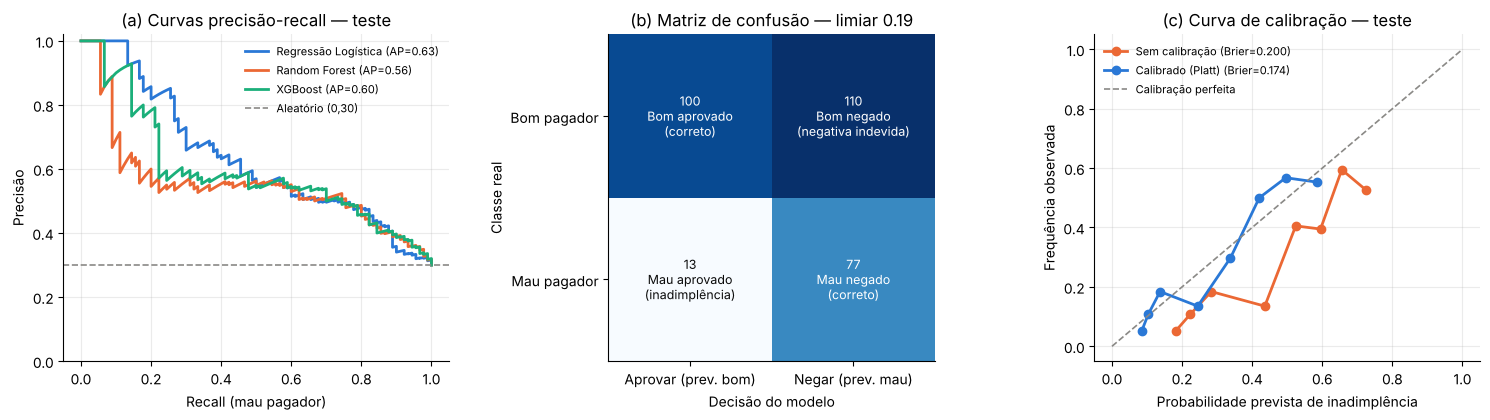

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# (a) Curvas precisão-recall dos melhores de cada família (teste)
ax = axes[0]
for n in ['LR', 'RF', 'XGB']:
    k = max([k for k in buscas if k[0] == n], key=lambda k: buscas[k].best_score_)
    pr, rc, _ = precision_recall_curve(y_te, prob_te[k])
    ax.plot(rc, pr, color=CORES[n], lw=2, label=f'{NOMES[n]} (AP={cs.average_precision_score(y_te, prob_te[k]):.2f})')
ax.axhline(y_te.mean(), color=CORES['Base'], ls='--', lw=1.2, label='Aleatório (0,30)')
ax.set(xlabel='Recall (mau pagador)', ylabel='Precisão', title='(a) Curvas precisão-recall — teste', ylim=(0, 1.02))
ax.legend(frameon=False, fontsize=8, loc='upper right')

# (b) Matriz de confusão do modelo final
ax = axes[1]
cm = confusion_matrix(y_te, pred_final)
ax.imshow(cm, cmap='Blues'); ax.grid(False)
rot = [['Bom aprovado\n(correto)', 'Bom negado\n(negativa indevida)'], ['Mau aprovado\n(inadimplência)', 'Mau negado\n(correto)']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]}\n{rot[i][j]}', ha='center', va='center', fontsize=9,
                color='white' if cm[i, j] > cm.max() * 0.55 else '#0b0b0b')
ax.set_xticks([0, 1], ['Aprovar (prev. bom)', 'Negar (prev. mau)']); ax.set_yticks([0, 1], ['Bom pagador', 'Mau pagador'])
ax.set(xlabel='Decisão do modelo', ylabel='Classe real', title=f'(b) Matriz de confusão — limiar {LIMIAR:.2f}')

# (c) Curva de calibração
ax = axes[2]
for nome, p, cor in [('Sem calibração', prob_te[CHAVE], CORES['RF']), ('Calibrado (Platt)', p_final, CORES['LR'])]:
    fr, mp = calibration_curve(y_te, p, n_bins=8, strategy='quantile')
    ax.plot(mp, fr, 'o-', color=cor, lw=2, ms=6, label=f'{nome} (Brier={cs.brier_score_loss(y_te, p):.3f})')
ax.plot([0, 1], [0, 1], ls='--', color=CORES['Base'], lw=1.2, label='Calibração perfeita')
ax.set(xlabel='Probabilidade prevista de inadimplência', ylabel='Frequência observada', title='(c) Curva de calibração — teste')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'fig_avaliacao_teste.png'); plt.show()

### 7.2 Verificação das metas

In [15]:
metas = pd.DataFrame([
    ['M1', 'PR-AUC ≥ 0,50', mf['PR-AUC'], mf['PR-AUC'] >= 0.50],
    ['M2', 'Recall (mau) ≥ 0,70', mf['Recall (mau)'], mf['Recall (mau)'] >= 0.70],
    ['M3', 'F1 (mau) ≥ 0,55', mf['F1 (mau)'], mf['F1 (mau)'] >= 0.55],
    ['M4', 'Custo/cliente ≤ 0,60', mf['Custo/cliente'], mf['Custo/cliente'] <= 0.60],
    ['M5a', 'Brier < 0,21', mf['Brier'], mf['Brier'] < 0.21],
    ['M5b', 'ECE ≤ 0,05', mf['ECE'], mf['ECE'] <= 0.05],
], columns=['Meta', 'Critério', 'Resultado (teste)', 'Atingida?'])
metas.to_csv(RES / 'tabela_metas.csv', index=False)
metas

,Meta,Critério,Resultado (teste),Atingida?
0,M1,"PR-AUC ≥ 0,50",0.564,True
1,M2,"Recall (mau) ≥ 0,70",0.856,True
2,M3,"F1 (mau) ≥ 0,55",0.556,True
3,M4,"Custo/cliente ≤ 0,60",0.583,True
4,M5a,"Brier < 0,21",0.174,True
5,M5b,"ECE ≤ 0,05",0.059,False


### 7.3 Custo × inclusão: efeito da razão de custos sobre a negativa indevida

A matriz 5:1 é uma escolha normativa da instituição de origem. Quanto maior o custo atribuído a aprovar um mau pagador,
menor o limiar e maior a quantidade de bons pagadores negados — o que vai contra a inclusão financeira (ODS 8 e 10).
Para tornar esse compromisso explícito, o limiar é recalculado (sempre nas predições fora da dobra do treino) para
outras razões de custo, e as consequências são medidas no teste.

,Razão de custo FN:FP,Limiar,Recall (mau),Negativa indevida (FPR),Taxa de aprovação,Maus aprovados (FN),Bons negados (FP)
0,1:1,0.490,0.333,0.119,0.817,60,25
1,2:1,0.335,0.744,0.310,0.560,23,65
2,3:1,0.315,0.767,0.329,0.540,21,69
3,5:1,0.190,0.856,0.524,0.377,13,110


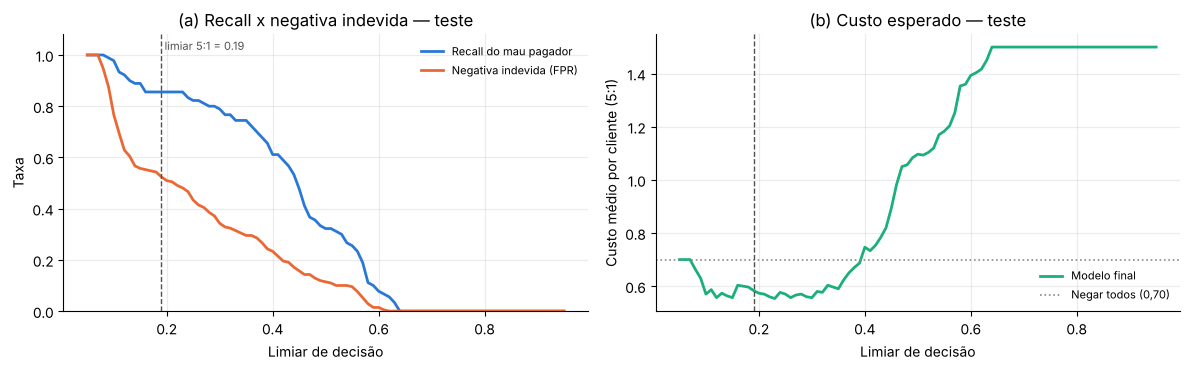

In [16]:
def limiar_custo(y_, p_, c_fn, c_fp=1.0):
    grid = np.round(np.arange(0.05, 0.951, 0.005), 3)
    custos = [(c_fn * ((y_ == 1) & (p_ < t)).sum() + c_fp * ((y_ == 0) & (p_ >= t)).sum()) / len(y_) for t in grid]
    return float(grid[int(np.argmin(custos))])

linhas = []
for razao in [1, 2, 3, 5]:
    t = limiar_custo(y_tr.values, oof_cal, razao)
    pr = (p_final >= t).astype(int)
    r = cs.group_rates(y_te.values, pr)
    linhas.append({'Razão de custo FN:FP': f'{razao}:1', 'Limiar': t, 'Recall (mau)': r['TPR (recall mau)'],
                   'Negativa indevida (FPR)': r['FPR (negativa indevida)'], 'Taxa de aprovação': r['taxa_aprovacao'],
                   'Maus aprovados (FN)': int(((y_te.values == 1) & (pr == 0)).sum()),
                   'Bons negados (FP)': int(((y_te.values == 0) & (pr == 1)).sum())})
tab_razao = pd.DataFrame(linhas)
tab_razao.to_csv(RES / 'tabela_razao_custo.csv', index=False)
display(tab_razao)

grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
rec = [((p_final >= t) & (y_te.values == 1)).sum() / (y_te.values == 1).sum() for t in grid]
fpr = [((p_final >= t) & (y_te.values == 0)).sum() / (y_te.values == 0).sum() for t in grid]
cst = [cs.expected_cost(y_te, (p_final >= t).astype(int)) for t in grid]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.plot(grid, rec, color=CORES['LR'], lw=2, label='Recall do mau pagador')
ax.plot(grid, fpr, color=CORES['RF'], lw=2, label='Negativa indevida (FPR)')
ax.axvline(LIMIAR, color='#52514e', ls='--', lw=1); ax.text(LIMIAR, 1.02, f' limiar 5:1 = {LIMIAR:.2f}', fontsize=8, color='#52514e')
ax.set(xlabel='Limiar de decisão', ylabel='Taxa', ylim=(0, 1.08), title='(a) Recall x negativa indevida — teste')
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.plot(grid, cst, color=CORES['XGB'], lw=2, label='Modelo final')
ax.axhline(0.70, color=CORES['Base'], ls=':', lw=1.2, label='Negar todos (0,70)')
ax.axvline(LIMIAR, color='#52514e', ls='--', lw=1)
ax.set(xlabel='Limiar de decisão', ylabel='Custo médio por cliente (5:1)', title='(b) Custo esperado — teste')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'fig_custo_inclusao.png'); plt.show()

## 8. Explicabilidade com SHAP

O SHAP é aplicado ao modelo selecionado **antes** da calibração. Como a calibração de Platt é uma
transformação monotônica do escore, a ordem dos clientes e o sentido de cada contribuição são preservados.
As contribuições das colunas *one-hot* de uma mesma variável são somadas (propriedade de aditividade do SHAP)
para apresentar a importância por variável original.

In [17]:
modelo_base = clone(base_final).fit(X_tr, y_tr)
prep, est = modelo_base.named_steps['prep'], modelo_base.named_steps['model']
cols_t = prep.get_feature_names_out()
Xt_tr = pd.DataFrame(prep.transform(X_tr), columns=cols_t)
Xt_te = pd.DataFrame(prep.transform(X_te), columns=cols_t)

if CHAVE[0] == 'LR':
    explainer = shap.LinearExplainer(est, Xt_tr)
else:
    explainer = shap.TreeExplainer(est)
sv = explainer(Xt_te)
vals = sv.values[..., 1] if sv.values.ndim == 3 else sv.values
bv = np.asarray(sv.base_values)
base_val = float(np.ravel(bv[..., 1] if bv.ndim == 2 else bv)[0])

def origem(col):
    for c in cs.CAT_COLS:
        if col.startswith(c + '_'):
            return c
    return col
grupos = pd.Series([origem(c) for c in cols_t])
sv_var = pd.DataFrame(vals, columns=cols_t).T.groupby(grupos.values).sum().T
imp = sv_var.abs().mean().sort_values(ascending=False)
imp.to_csv(RES / 'tabela_importancia_shap.csv', header=['media_abs_shap'])
imp.round(4)

Checking account    0.155
Duration            0.043
Saving accounts     0.035
Credit amount       0.019
Housing             0.012
Age                 0.010
Sex                 0.007
Purpose             0.007
Job                 0.002
dtype: float64

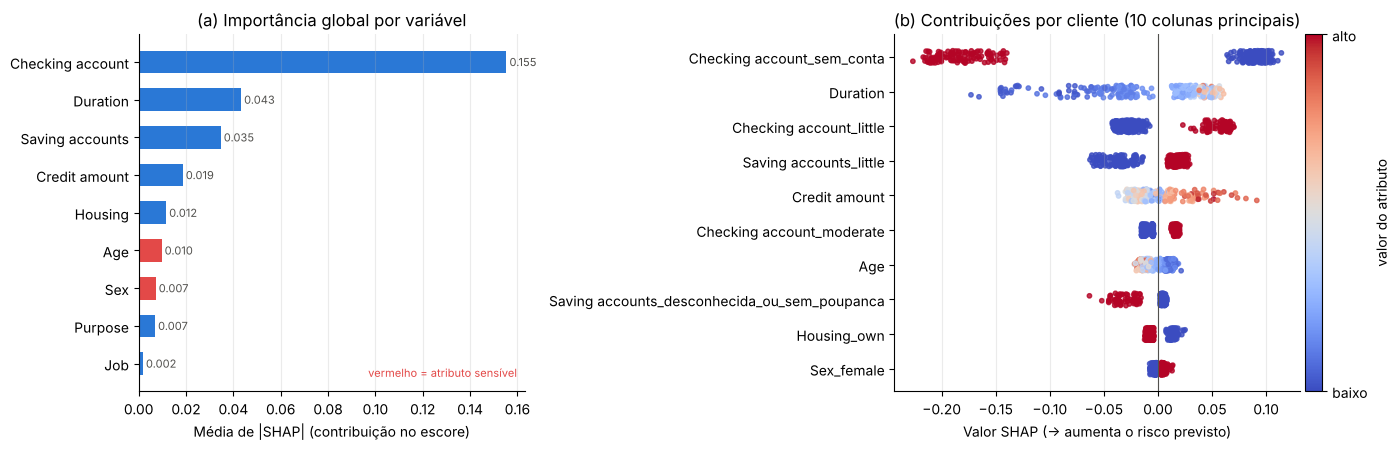

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1.25]})
ax = axes[0]
imp_plot = imp.sort_values()
cores_bar = ['#e34948' if v in cs.SENSITIVE else CORES['LR'] for v in imp_plot.index]
ax.barh(imp_plot.index, imp_plot.values, color=cores_bar, height=0.6)
for i, v in enumerate(imp_plot.values):
    ax.text(v, i, f' {v:.3f}', va='center', fontsize=8, color='#52514e')
ax.set(xlabel='Média de |SHAP| (contribuição no escore)', title='(a) Importância global por variável')
ax.grid(axis='y', visible=False)
ax.text(0.98, 0.04, 'vermelho = atributo sensível', transform=ax.transAxes, ha='right', fontsize=8, color='#e34948')

# (b) dispersão das contribuições das 10 colunas mais importantes
top = pd.Series(np.abs(vals).mean(0), index=cols_t).sort_values(ascending=False).index[:10][::-1]
ax = axes[1]
for i, c in enumerate(top):
    x = vals[:, list(cols_t).index(c)]
    f = Xt_te[c].values
    fn = (f - f.min()) / (f.max() - f.min() + 1e-9)
    ax.scatter(x, i + np.random.uniform(-0.18, 0.18, len(x)), c=fn, cmap='coolwarm', s=10, alpha=0.8)
ax.set_yticks(range(len(top)), top); ax.axvline(0, color='#52514e', lw=0.8)
ax.set(xlabel='Valor SHAP (→ aumenta o risco previsto)', title='(b) Contribuições por cliente (10 colunas principais)')
ax.grid(axis='y', visible=False)
sm = plt.cm.ScalarMappable(cmap='coolwarm'); sm.set_array([])
cb = plt.colorbar(sm, ax=ax, pad=0.01); cb.set_ticks([0, 1]); cb.set_ticklabels(['baixo', 'alto']); cb.set_label('valor do atributo')
plt.tight_layout(); plt.savefig(FIG / 'fig_shap_global.png'); plt.show()

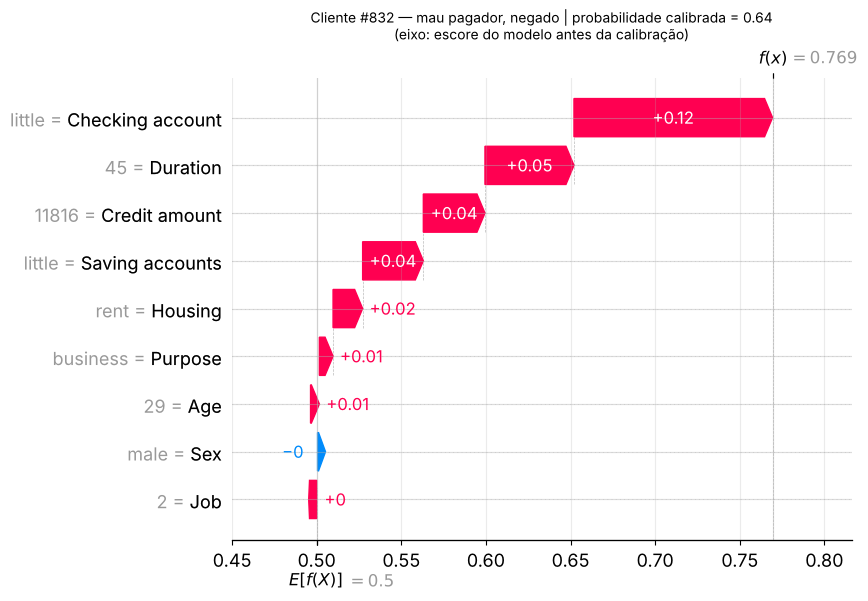

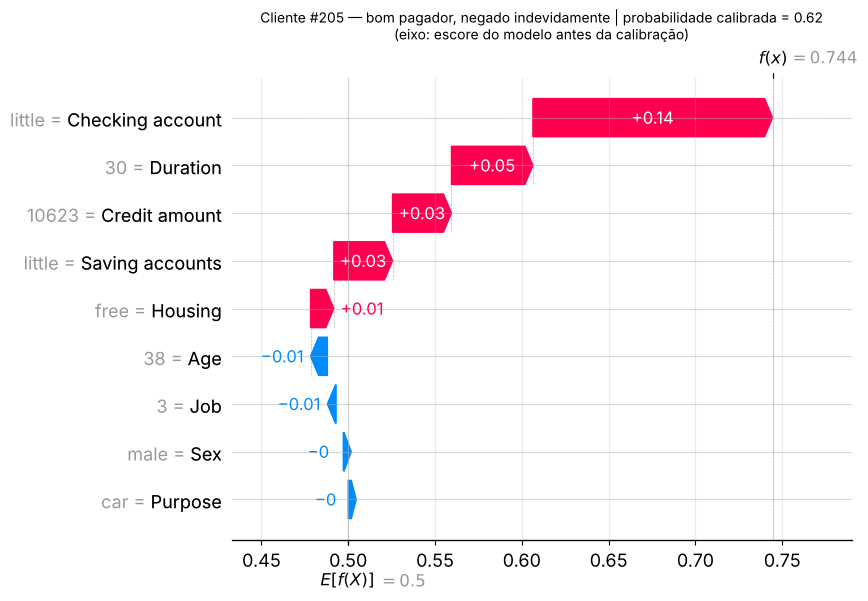

In [19]:
# Explicações locais: um mau pagador negado corretamente e um bom pagador negado indevidamente (se houver)
def explica(i, titulo, arquivo):
    e = shap.Explanation(values=sv_var.iloc[i].values, base_values=base_val,
                         data=X_te.iloc[i][sv_var.columns].values, feature_names=list(sv_var.columns))
    plt.figure()
    shap.plots.waterfall(e, max_display=10, show=False)
    plt.title(titulo, fontsize=10); plt.savefig(FIG / arquivo); plt.show()

idx_tp = np.where((y_te.values == 1) & (pred_final == 1))[0]
idx_fp = np.where((y_te.values == 0) & (pred_final == 1))[0]
i_tp = idx_tp[np.argmax(p_final[idx_tp])]
explica(i_tp, f'Cliente #{X_te.index[i_tp]} — mau pagador, negado | probabilidade calibrada = {p_final[i_tp]:.2f}\n(eixo: escore do modelo antes da calibração)', 'fig_shap_local_mau.png')
if len(idx_fp):
    i_fp = idx_fp[np.argmax(p_final[idx_fp])]
    explica(i_fp, f'Cliente #{X_te.index[i_fp]} — bom pagador, negado indevidamente | probabilidade calibrada = {p_final[i_fp]:.2f}\n(eixo: escore do modelo antes da calibração)', 'fig_shap_local_fp.png')

## 9. Avaliação de equidade (taxas de erro entre grupos, com incerteza)

Diferenças na **proporção real** de maus pagadores entre grupos (observadas na N1) não comprovam discriminação do
modelo. A equidade é avaliada pelas **taxas de erro** do modelo dentro de cada grupo:

* **TPR (recall do mau pagador)** — igualdade de oportunidade (Hardt et al., 2016);
* **FPR (negativa indevida de bons pagadores)** — o erro que afeta diretamente a inclusão financeira;
* **taxa de aprovação** e **razão de aprovação** (regra dos 4/5, apenas como referência).

Grupos: **sexo** (referência: masculino) e **faixa etária** (referência: 26 anos ou mais, comparada com até 25).
São reportadas estimativas com IC 95% por *bootstrap* em duas bases: (i) o **teste** (300 clientes) e (ii) as predições
**fora da dobra para os 1.000 clientes** (validação cruzada do procedimento completo, com o mesmo limiar), que reduzem a
incerteza por usar toda a base.

In [20]:
def tabela_grupos(y_, pred_, X_):
    linhas = []
    for var, g in [('Sexo', X_['Sex'].values), ('Idade', cs.age_group(X_['Age']).astype(str).values)]:
        for nivel in pd.unique(g):
            r = cs.group_rates(y_[g == nivel], pred_[g == nivel])
            linhas.append({'Atributo': var, 'Grupo': nivel, **r})
    return pd.DataFrame(linhas)

def gaps_todos(y_, pred_, X_):
    a = cs.fairness_gaps(y_, pred_, X_['Sex'].values, 'male', 'female')
    a.index = ['Sexo: ' + i + ' (fem − masc)' for i in a.index]
    b = cs.fairness_gaps(y_, pred_, cs.age_group(X_['Age']).astype(str).values, '26 ou mais', 'ate 25')
    b.index = ['Idade: ' + i + ' (≤25 − 26+)' for i in b.index]
    return pd.concat([a, b])

print('(i) Conjunto de teste')
grupos_teste = tabela_grupos(y_te.values, pred_final, X_te)
display(grupos_teste)
gaps_teste = gaps_todos(y_te.values, pred_final, X_te)
gaps_teste

(i) Conjunto de teste


,Atributo,Grupo,n,taxa_real_mau,taxa_aprovacao,TPR (recall mau),FPR (negativa indevida),FNR (mau aprovado)
0,Sexo,male,199,0.276,0.397,0.855,0.507,0.145
1,Sexo,female,101,0.347,0.337,0.857,0.561,0.143
2,Idade,26 ou mais,234,0.256,0.406,0.867,0.500,0.133
3,Idade,ate 25,66,0.455,0.273,0.833,0.639,0.167


,estimativa,IC95_inf,IC95_sup
Sexo: Delta TPR (recall mau) (fem − masc),0.003,-0.154,0.145
Sexo: Delta FPR (negativa indevida) (fem − masc),0.054,-0.094,0.190
Sexo: Delta taxa de aprovacao (fem − masc),-0.060,-0.168,0.059
Sexo: Razao de aprovacao (fem − masc),0.848,0.611,1.160
Idade: Delta TPR (recall mau) (≤25 − 26+),-0.033,-0.212,0.122
Idade: Delta FPR (negativa indevida) (≤25 − 26+),0.139,-0.040,0.307
Idade: Delta taxa de aprovacao (≤25 − 26+),-0.133,-0.257,-0.001
Idade: Razao de aprovacao (≤25 − 26+),0.672,0.408,0.997


In [21]:
# (ii) Predições fora da dobra para toda a base (procedimento completo: busca já fixada + calibração + limiar)
p_all = oof_proba(CalibratedClassifierCV(base_final, method='sigmoid', cv=5), X, y, repeats=3)
pred_all = (p_all >= LIMIAR).astype(int)
print('Desempenho OOF na base completa:', {k: round(v, 3) for k, v in cs.all_metrics(y.values, p_all, LIMIAR).items()
                                          if k in ['PR-AUC', 'Recall (mau)', 'F1 (mau)', 'Custo/cliente']})
grupos_oof = tabela_grupos(y.values, pred_all, X)
display(grupos_oof)
gaps_oof = gaps_todos(y.values, pred_all, X)
grupos_oof.to_csv(RES / 'tabela_equidade_grupos_oof.csv', index=False)
gaps_oof.to_csv(RES / 'tabela_equidade_gaps_oof.csv')
gaps_teste.to_csv(RES / 'tabela_equidade_gaps_teste.csv')
gaps_oof

Desempenho OOF na base completa: {'PR-AUC': 0.549, 'F1 (mau)': 0.565, 'Recall (mau)': 0.87, 'Custo/cliente': np.float64(0.558)}


,Atributo,Grupo,n,taxa_real_mau,taxa_aprovacao,TPR (recall mau),FPR (negativa indevida),FNR (mau aprovado)
0,Sexo,male,690,0.277,0.390,0.869,0.511,0.131
1,Sexo,female,310,0.352,0.345,0.872,0.537,0.128
2,Idade,26 ou mais,810,0.272,0.409,0.855,0.493,0.145
3,Idade,ate 25,190,0.421,0.237,0.912,0.655,0.088


,estimativa,IC95_inf,IC95_sup
Sexo: Delta TPR (recall mau) (fem − masc),0.002,-0.077,0.078
Sexo: Delta FPR (negativa indevida) (fem − masc),0.026,-0.056,0.109
Sexo: Delta taxa de aprovacao (fem − masc),-0.045,-0.109,0.021
Sexo: Razao de aprovacao (fem − masc),0.885,0.737,1.060
Idade: Delta TPR (recall mau) (≤25 − 26+),0.058,-0.021,0.133
Idade: Delta FPR (negativa indevida) (≤25 − 26+),0.161,0.058,0.258
Idade: Delta taxa de aprovacao (≤25 − 26+),-0.172,-0.238,-0.104
Idade: Razao de aprovacao (≤25 − 26+),0.580,0.432,0.741


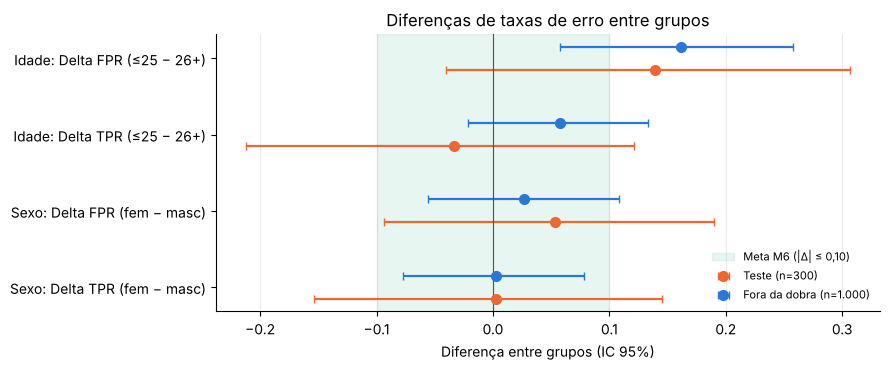

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.8))
sel_rows = [i for i in gaps_oof.index if 'TPR' in i or 'FPR' in i]
ypos = np.arange(len(sel_rows))
for off, (tab, cor, rot) in zip([-0.15, 0.15], [(gaps_teste, CORES['RF'], 'Teste (n=300)'), (gaps_oof, CORES['LR'], 'Fora da dobra (n=1.000)')]):
    t = tab.loc[sel_rows]
    ax.errorbar(t['estimativa'], ypos + off, xerr=[t['estimativa'] - t['IC95_inf'], t['IC95_sup'] - t['estimativa']],
                fmt='o', color=cor, ms=7, capsize=3, lw=1.6, label=rot)
ax.axvspan(-0.10, 0.10, color='#1baf7a', alpha=0.10, label='Meta M6 (|Δ| ≤ 0,10)')
ax.axvline(0, color='#52514e', lw=0.8)
ax.set_yticks(ypos, [s.replace(' (recall mau)', '').replace(' (negativa indevida)', '') for s in sel_rows])
ax.set(xlabel='Diferença entre grupos (IC 95%)', title='Diferenças de taxas de erro entre grupos')
ax.legend(frameon=False, fontsize=8, loc='lower right'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(FIG / 'fig_equidade.png'); plt.show()

## 10. Medida de mitigação testada: remoção dos atributos sensíveis

Como medida concreta, o mesmo modelo (mesmos hiperparâmetros) é retreinado **sem `Sex`** e **sem `Sex` e `Age`**.
A comparação mostra o efeito sobre desempenho e sobre as diferenças entre grupos. A remoção não garante equidade,
pois outras variáveis podem funcionar como *proxy* (por exemplo, moradia e qualificação profissional se associam a idade
e sexo); por isso o efeito é medido, e não presumido.

In [23]:
from sklearn.base import clone as _clone
def variante(sem):
    num = [c for c in cs.NUM_COLS if c not in sem]
    cat = [c for c in cs.CAT_COLS if c not in sem]
    pipe = cs.make_pipeline(CHAVE[0], CHAVE[1], num_cols=num, cat_cols=cat)
    pipe.set_params(**buscas[CHAVE].best_params_)
    cal = CalibratedClassifierCV(pipe, method='sigmoid', cv=5)
    Xv = X.drop(columns=list(sem))
    p_oof_tr = oof_proba(cal, X_tr.drop(columns=list(sem)), y_tr)
    lim = cs.best_cost_threshold(y_tr.values, p_oof_tr)
    p = oof_proba(cal, Xv, y, repeats=3)
    pr = (p >= lim).astype(int)
    m = cs.all_metrics(y.values, p, lim)
    g = gaps_todos(y.values, pr, X)
    return m, g, lim

resultado_mit = {'Completo (9 variáveis)': (cs.all_metrics(y.values, p_all, LIMIAR), gaps_oof, LIMIAR)}
for nome_v, sem in [('Sem Sex', ['Sex']), ('Sem Sex e Age', ['Sex', 'Age'])]:
    resultado_mit[nome_v] = variante(sem)

linhas = []
for nome_v, (m, g, lim) in resultado_mit.items():
    linhas.append({'Variante': nome_v, 'Limiar': lim, 'PR-AUC': m['PR-AUC'], 'Recall (mau)': m['Recall (mau)'],
                   'Custo/cliente': m['Custo/cliente'],
                   'ΔTPR sexo': g.iloc[0]['estimativa'], 'ΔFPR sexo': g.iloc[1]['estimativa'],
                   'ΔTPR idade': g.iloc[4]['estimativa'], 'ΔFPR idade': g.iloc[5]['estimativa']})
tab_mit = pd.DataFrame(linhas)
tab_mit.to_csv(RES / 'tabela_mitigacao.csv', index=False)
tab_mit

,Variante,Limiar,PR-AUC,Recall (mau),Custo/cliente,ΔTPR sexo,ΔFPR sexo,ΔTPR idade,ΔFPR idade
0,Completo (9 variáveis),0.190,0.549,0.870,0.558,0.002,0.026,0.058,0.161
1,Sem Sex,0.185,0.550,0.870,0.562,-0.012,0.011,0.041,0.155
2,Sem Sex e Age,0.185,0.556,0.867,0.568,-0.021,0.002,0.028,0.153


In [24]:
for nome_v, (m, g, lim) in resultado_mit.items():
    print(nome_v)
    display(g.loc[[i for i in g.index if 'TPR' in i or 'FPR' in i]])

Completo (9 variáveis)


,estimativa,IC95_inf,IC95_sup
Sexo: Delta TPR (recall mau) (fem − masc),0.002,-0.077,0.078
Sexo: Delta FPR (negativa indevida) (fem − masc),0.026,-0.056,0.109
Idade: Delta TPR (recall mau) (≤25 − 26+),0.058,-0.021,0.133
Idade: Delta FPR (negativa indevida) (≤25 − 26+),0.161,0.058,0.258


Sem Sex


,estimativa,IC95_inf,IC95_sup
Sexo: Delta TPR (recall mau) (fem − masc),-0.012,-0.094,0.067
Sexo: Delta FPR (negativa indevida) (fem − masc),0.011,-0.070,0.094
Idade: Delta TPR (recall mau) (≤25 − 26+),0.041,-0.040,0.119
Idade: Delta FPR (negativa indevida) (≤25 − 26+),0.155,0.052,0.251


Sem Sex e Age


,estimativa,IC95_inf,IC95_sup
Sexo: Delta TPR (recall mau) (fem − masc),-0.021,-0.103,0.058
Sexo: Delta FPR (negativa indevida) (fem − masc),0.002,-0.078,0.082
Idade: Delta TPR (recall mau) (≤25 − 26+),0.028,-0.053,0.109
Idade: Delta FPR (negativa indevida) (≤25 − 26+),0.153,0.051,0.247


### 10.1 A disparidade depende do algoritmo?

Para saber se a diferença entre faixas etárias é específica do modelo selecionado ou aparece em todos, a mesma avaliação
(predições fora da dobra para os 1.000 clientes, calibração de Platt e limiar de custo escolhido no treino) é repetida
com a melhor configuração de cada algoritmo.

In [25]:
linhas = []
for n in ['LR', 'RF', 'XGB']:
    k = max([k for k in buscas if k[0] == n], key=lambda k: buscas[k].best_score_)
    cal_k = CalibratedClassifierCV(buscas[k].best_estimator_, method='sigmoid', cv=5)
    lim_k = LIMIAR if k == CHAVE else cs.best_cost_threshold(y_tr.values, oof_proba(cal_k, X_tr, y_tr))
    p_k = p_all if k == CHAVE else oof_proba(cal_k, X, y, repeats=3)
    g_k = gaps_todos(y.values, (p_k >= lim_k).astype(int), X)
    linhas.append({'Modelo': f'{NOMES[n]} ({BAL[k[1]]})', 'Limiar': lim_k,
                   'PR-AUC (OOF)': cs.average_precision_score(y, p_k),
                   'Custo/cliente (OOF)': cs.expected_cost(y, (p_k >= lim_k).astype(int)),
                   'ΔFPR idade [IC95]': f"{g_k.iloc[5, 0]:+.3f} [{g_k.iloc[5, 1]:+.3f}; {g_k.iloc[5, 2]:+.3f}]",
                   'ΔTPR idade [IC95]': f"{g_k.iloc[4, 0]:+.3f} [{g_k.iloc[4, 1]:+.3f}; {g_k.iloc[4, 2]:+.3f}]",
                   'ΔFPR sexo [IC95]': f"{g_k.iloc[1, 0]:+.3f} [{g_k.iloc[1, 1]:+.3f}; {g_k.iloc[1, 2]:+.3f}]"})
tab_alg = pd.DataFrame(linhas)
tab_alg.to_csv(RES / 'tabela_equidade_por_algoritmo.csv', index=False)
tab_alg

,Modelo,Limiar,PR-AUC (OOF),Custo/cliente (OOF),ΔFPR idade [IC95],ΔTPR idade [IC95],ΔFPR sexo [IC95]
0,Regressão Logística (peso de classe),0.235,0.565,0.561,+0.258 [+0.156; +0.357],+0.095 [+0.008; +0.175],+0.085 [+0.003; +0.166]
1,Random Forest (peso de classe),0.190,0.549,0.558,+0.161 [+0.058; +0.258],+0.058 [-0.021; +0.133],+0.026 [-0.056; +0.109]
2,XGBoost (peso de classe),0.280,0.553,0.607,+0.281 [+0.184; +0.376],+0.122 [+0.027; +0.212],+0.065 [-0.015; +0.148]


### 10.2 Pós-processamento: limiar específico por faixa etária (demonstração)

Outra medida concreta é ajustar o limiar do grupo prejudicado para igualar a taxa de negativa indevida (FPR) à do grupo
de referência. O limiar do grupo "até 25 anos" é escolhido **no treino** (predições fora da dobra) e aplicado ao teste.
Essa medida exige usar a idade explicitamente na decisão, o que levanta questões jurídicas (princípio da não discriminação,
art. 6º, IX, da LGPD) e precisa ser avaliada antes de qualquer uso real; aqui ela serve para **quantificar o compromisso**
entre equidade e custo.

In [26]:
g_tr = cs.age_group(X_tr['Age']).astype(str).values
g_te = cs.age_group(X_te['Age']).astype(str).values
neg_ref = (y_tr.values == 0) & (g_tr == '26 ou mais')
neg_jov = (y_tr.values == 0) & (g_tr == 'ate 25')
fpr_ref = (oof_cal[neg_ref] >= LIMIAR).mean()
grid = np.round(np.arange(0.05, 0.951, 0.005), 3)
T_JOVEM = float(grid[np.argmin([abs((oof_cal[neg_jov] >= t).mean() - fpr_ref) for t in grid])])
print(f'FPR de referência (26+, treino OOF): {fpr_ref:.3f} -> limiar para até 25 anos: {T_JOVEM:.3f} (geral: {LIMIAR:.3f})')

pred_pp = np.where(g_te == 'ate 25', p_final >= T_JOVEM, p_final >= LIMIAR).astype(int)
linhas = []
for nome_v, pr in [('Limiar único', pred_final), ('Limiar por faixa etária', pred_pp)]:
    g = gaps_todos(y_te.values, pr, X_te)
    r = cs.group_rates(y_te.values, pr)
    linhas.append({'Política': nome_v, 'Recall (mau)': r['TPR (recall mau)'], 'FPR geral': r['FPR (negativa indevida)'],
                   'Custo/cliente': cs.expected_cost(y_te, pr),
                   'ΔFPR idade [IC95]': f"{g.iloc[5, 0]:+.3f} [{g.iloc[5, 1]:+.3f}; {g.iloc[5, 2]:+.3f}]",
                   'ΔTPR idade [IC95]': f"{g.iloc[4, 0]:+.3f} [{g.iloc[4, 1]:+.3f}; {g.iloc[4, 2]:+.3f}]"})
tab_pp = pd.DataFrame(linhas)
tab_pp.to_csv(RES / 'tabela_pos_processamento_idade.csv', index=False)
tab_pp

FPR de referência (26+, treino OOF): 0.498 -> limiar para até 25 anos: 0.360 (geral: 0.190)


,Política,Recall (mau),FPR geral,Custo/cliente,ΔFPR idade [IC95],ΔTPR idade [IC95]
0,Limiar único,0.856,0.524,0.583,+0.139 [-0.040; +0.307],-0.033 [-0.212; +0.122]
1,Limiar por faixa etária,0.800,0.495,0.647,-0.028 [-0.212; +0.156],-0.200 [-0.399; -0.011]


## 11. Análise de sensibilidade: custo da redução de 20 para 9 atributos

O mesmo algoritmo e estratégia de balanceamento do modelo selecionado são ajustados (busca aleatória idêntica) com os
20 atributos originais do UCI, na mesma divisão treino/teste. A diferença de PR-AUC quantifica a informação perdida na
versão simplificada.

In [27]:
o = orig.drop(columns=['class']).copy()
y_o = (orig['class'] == 2).astype(int)
num_o = ['duration', 'amount', 'installment_rate', 'residence', 'age', 'n_credits', 'liable']
cat_o = [c for c in o.columns if c not in num_o]
o = o.rename(columns={'amount': 'Credit amount'}); num_o[1] = 'Credit amount'
pipe_o = cs.make_pipeline(CHAVE[0], CHAVE[1], num_cols=num_o, cat_cols=cat_o)
busca_o = RandomizedSearchCV(pipe_o, ESPACOS[CHAVE[0]], n_iter=N_ITER[CHAVE[0]], scoring='average_precision',
                             cv=CV_TUNE, random_state=cs.SEED, n_jobs=2)
busca_o.fit(o.loc[X_tr.index], y_o.loc[X_tr.index])
p_o = busca_o.predict_proba(o.loc[X_te.index])[:, 1]
sens = pd.DataFrame({
    'PR-AUC (CV treino)': [buscas[CHAVE].best_score_, busca_o.best_score_],
    'PR-AUC (teste)': [cs.average_precision_score(y_te, prob_te[CHAVE]), cs.average_precision_score(y_te, p_o)],
    'ROC-AUC (teste)': [cs.roc_auc_score(y_te, prob_te[CHAVE]), cs.roc_auc_score(y_te, p_o)],
}, index=['9 atributos (versão simplificada)', '20 atributos (UCI original)'])
sens.to_csv(RES / 'tabela_sensibilidade_20_atributos.csv')
sens

,PR-AUC (CV treino),PR-AUC (teste),ROC-AUC (teste)
9 atributos (versão simplificada),0.586,0.556,0.756
20 atributos (UCI original),0.624,0.623,0.795


## 12. Modelo final salvo e demonstração de uso

In [28]:
pacote = {
    'modelo_calibrado': calibrado,       # usado para a probabilidade e a decisão
    'modelo_base': modelo_base,          # usado para as explicações SHAP
    'limiar': LIMIAR,
    'configuracao': {'algoritmo': NOMES[CHAVE[0]], 'balanceamento': BAL[CHAVE[1]],
                     'hiperparametros': buscas[CHAVE].best_params_},
    'custos': {'FN (mau aprovado)': cs.COST_FN, 'FP (bom negado)': cs.COST_FP},
    'metricas_teste': {k: float(v) for k, v in mf.items()},
    'colunas': list(X.columns),
}
joblib.dump(pacote, MOD / 'credscore_modelo_final.joblib')
print('Modelo salvo em', MOD / 'credscore_modelo_final.joblib')

novo = pd.DataFrame([{'Age': 23, 'Sex': 'female', 'Job': 2, 'Housing': 'rent',
                      'Saving accounts': 'little', 'Checking account': 'little',
                      'Credit amount': 6000, 'Duration': 36, 'Purpose': 'car'}])
p_novo = calibrado.predict_proba(novo)[0, 1]
print(f'Cliente hipotético: P(inadimplência) = {p_novo:.1%} -> '
      f'{"NEGAR / encaminhar para análise humana" if p_novo >= LIMIAR else "APROVAR"} (limiar {LIMIAR:.2f})')

Modelo salvo em ../modelos/credscore_modelo_final.joblib


Cliente hipotético: P(inadimplência) = 63.4% -> NEGAR / encaminhar para análise humana (limiar 0.19)


## 13. Conclusões

* **Seleção e desempenho.** As seis configurações ficaram próximas na validação cruzada (PR-AUC de 0,560 a 0,586, diferenças menores que o desvio-padrão). O Random Forest com peso de classe foi selecionado pelo critério definido (maior PR-AUC média), mas no teste a Regressão Logística teve PR-AUC maior (0,635 contra 0,556; diferença pareada −0,068, IC 95% −0,131 a −0,007) e custo equivalente (diferença +0,032, IC 95% −0,063 a +0,117). Em base pequena, a complexidade adicional não trouxe ganho.
* **Modelo final (calibrado, limiar 0,190).** PR-AUC 0,564; recall 0,856; F1 0,556; custo 0,583 por cliente; Brier 0,174; ECE 0,059. Metas M1–M5a atingidas; M5b (ECE ≤ 0,05) não atingida por pouco; o IC do custo inclui o custo de "negar todos" (0,70).
* **Custo × inclusão.** Com a matriz 5:1, 52% dos bons pagadores são negados; com 2:1, a negativa indevida cai para 31% e o recall para 0,74. A razão de custo é uma escolha normativa tão importante quanto o algoritmo.
* **SHAP.** Conta corrente é o fator dominante, seguida de prazo, poupança e valor; sexo e idade têm baixa importância direta.
* **Equidade.** Sem diferença relevante entre sexos. Bons pagadores de até 25 anos são negados indevidamente com mais frequência (ΔFPR = +0,161, IC 95% +0,058 a +0,258), meta M6 não atingida. A disparidade persiste sem sexo e idade (proxies), é maior na Regressão Logística e no XGBoost, e o limiar por faixa etária iguala a FPR à custa de recall menor para os jovens e custo maior.
* **Simplificação da base.** Com os 20 atributos originais, a PR-AUC no teste sobe de 0,556 para 0,623.

O modelo é uma prova de conceito acadêmica e não deve ser usado em decisões reais; o protótipo apresenta recomendações sujeitas à revisão humana.
